
H3 Adaptive Cybersecurity Response Validation

H3: Cybersecurity analytics reduces the operational impact of simulated denial-of-service conditions in RFID baggage tracking environments.

RQ3: How effective are cybersecurity analytics in reducing denial-of-service risks in baggage tracking?

This notebook extends the H3 analysis by comparing automatic buffering, traditional rule detection, and Machine Learning detection with simulated cybersecurity responses. The prepared RFID baggage tracking data and CICIDS2017 network traffic data are used to evaluate whether cybersecurity analytics provides additional operational benefits beyond automatic buffering.

BLUF: The analysis examines whether cybersecurity analytics, combined with automatic buffering and a simulated security response, reduces RFID event losses, incomplete custody paths, and service interruptions compared to buffering alone.


Step 1: Connect and Review the Prepared RFID Data

The prepared RFID baggage tracking file was connected from the Praxis project folder. The data was reviewed to confirm the number of scan records, baggage journeys, denial of service records, and disruption groups before the H3 validation continued.


In [1]:

# Step 1: Connect and review the prepared RFID data


# Load the libraries

import pandas as pd
import os


# Set the main project folder

main_folder = os.getcwd()


# Check the project folder

if not os.path.isdir(main_folder + "/06_Prepared_Data"):
    main_folder = os.path.dirname(main_folder)


# Set the prepared data folder

prepared_folder = main_folder + "/06_Prepared_Data"


# Set the prepared RFID file

prepared_file = (
    prepared_folder +
    "/02_Prepared_RFID_Data.csv"
)


# Load the prepared RFID data

h3_data = pd.read_csv(prepared_file)


print("The prepared RFID data is connected.")


# Check the dataset size

print(
    "\nTotal RFID records:",
    len(h3_data)
)

print(
    "Total columns:",
    len(h3_data.columns)
)

print(
    "Total baggage journeys:",
    h3_data["bag_id"].nunique()
)

print(
    "Unique scan IDs:",
    h3_data["scan_id"].nunique()
)


# Check the denial of service records

print(
    "\nDenial of Service scans:",
    (h3_data["scan_status"] == "Denial of Service").sum()
)

print(
    "DoS disruption records:",
    (h3_data["disruption_window"] == 1).sum()
)


# Create a separate copy of the DoS events

dos_events = h3_data[
    h3_data["disruption_window"] == 1
].copy()


# Check the affected baggage journeys and disruption groups

print(
    "Unique affected scans:",
    dos_events["scan_id"].nunique()
)

print(
    "Affected baggage journeys:",
    dos_events["bag_id"].nunique()
)

print(
    "Unique disruption IDs:",
    dos_events["disruption_id"].nunique()
)


print("\nStep 1 complete.")


The prepared RFID data is connected.

Total RFID records: 31575
Total columns: 34
Total baggage journeys: 5000
Unique scan IDs: 31575

Denial of Service scans: 75
DoS disruption records: 75
Unique affected scans: 75
Affected baggage journeys: 75
Unique disruption IDs: 10

Step 1 complete.



Step 2: Review the DoS Disruptions and Comparison Conditions

The 75 affected RFID scans were reviewed to confirm the number of baggage journeys and disruption durations associated with each simulated DoS event.

Four operating conditions were identified for the H3 validation: no mitigation, automatic buffering, buffering with traditional rule detection, and buffering with machine learning detection.

All four conditions will use the same disruption records. Automatic buffering will remain available under both detection conditions. This allows the analysis to examine whether an additional cybersecurity response improves operational recovery without making buffering dependent on an attack alert.


In [2]:

# Step 2: Review the DoS disruptions and comparison conditions

# Create a separate copy of the affected RFID records

h3_disruptions = dos_events.copy()

# Review the scans and baggage journeys for each disruption

disruption_summary = (
    h3_disruptions
    .groupby("disruption_id")
    .agg(
        affected_scans=("scan_id", "count"),
        affected_journeys=("bag_id", "nunique"),
        duration_minutes=("disruption_minutes", "first")
    )
    .reset_index()
)

# Display the disruption summary

print("H3 DoS disruption summary:")

print(disruption_summary.to_string(index=False))

# Confirm the disruption totals

print("\nTotal disruptions:", len(disruption_summary))

print("Total affected scans:", len(h3_disruptions))

print(
    "Total affected baggage journeys:",
    h3_disruptions["bag_id"].nunique()
)

# Identify the four comparison conditions

h3_conditions = pd.DataFrame({
    "Condition": [
        "No mitigation",
        "Automatic buffering",
        "Buffering with rule detection",
        "Buffering with analytics"
    ],
    "Buffering": [
        "No",
        "Yes",
        "Yes",
        "Yes"
    ],
    "Detection": [
        "None",
        "None",
        "Traditional rule",
        "Machine learning"
    ]
})

# Display the comparison conditions

print("\nH3 comparison conditions:")

print(h3_conditions.to_string(index=False))

# Verify that each disruption has one duration

duration_check = (
    h3_disruptions
    .groupby("disruption_id")["disruption_minutes"]
    .nunique()
)

print(
    "\nConsistent disruption durations:",
    (duration_check == 1).all()
)

# Confirm the original RFID data remains unchanged

print(
    "Original RFID records:",
    len(h3_data)
)

print("\nStep 2 complete.")


H3 DoS disruption summary:
disruption_id  affected_scans  affected_journeys  duration_minutes
        DOS01               8                  8                20
        DOS02               8                  8                16
        DOS03               8                  8                27
        DOS04               8                  8                29
        DOS05               8                  8                20
        DOS06               7                  7                17
        DOS07               7                  7                21
        DOS08               7                  7                17
        DOS09               7                  7                23
        DOS10               7                  7                17

Total disruptions: 10
Total affected scans: 75
Total affected baggage journeys: 75

H3 comparison conditions:
                    Condition Buffering        Detection
                No mitigation        No             None
          A


Step 3: Connect and Prepare the CICIDS2017 Network Data

The CICIDS2017 DDoS dataset was connected to examine normal and malicious network traffic. The analysis uses the same five network traffic measurements selected for the supplemental H3 experiment.

The network records were prepared to support a comparison between traditional rule detection and machine learning. Both methods will use the same training and testing records to provide a consistent evaluation.

The CICIDS2017 data represents network activity rather than actual airport baggage tracking traffic. Its detection results will be used to inform the simulated cybersecurity response.


In [3]:

# Step 3: Connect and prepare the CICIDS2017 network data


# Load the library

import numpy as np


# Set the CICIDS2017 file location

cicids_file = os.path.join(
    main_folder,
    "05_CICIDS2017",
    "data",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
)


# Select the network traffic measurements

h3_features = [
    "Flow Duration",
    "Flow Packets/s",
    "Flow Bytes/s",
    "Total Fwd Packets",
    "Total Backward Packets"
]


# Load the network data

h3_network = pd.read_csv(
    cicids_file,
    usecols=lambda name: name.strip() in h3_features + ["Label"]
)


# Clean the column names

h3_network.columns = h3_network.columns.str.strip()


# Clean the traffic labels

h3_network["Label"] = (
    h3_network["Label"].astype(str).str.strip().str.upper()
)


# Review the network records

print("CICIDS2017 network data connected.")

print("\nTotal network records:", len(h3_network))

print("\nNetwork traffic labels:")

print(h3_network["Label"].value_counts())


# Identify normal and attack traffic

h3_network["attack"] = (
    h3_network["Label"] == "DDOS"
).astype(int)


# Prepare the network measurements

X = h3_network[h3_features].apply(
    pd.to_numeric,
    errors="coerce"
)

X = X.replace([np.inf, -np.inf], np.nan)


# Prepare the attack labels

y = h3_network["attack"]


# Review the prepared data

print("\nSelected network measurements:", len(h3_features))

print("Normal traffic records:", (y == 0).sum())

print("DDoS attack records:", (y == 1).sum())

print("Missing measurement values:", X.isna().sum().sum())


# Confirm the expected traffic labels

print(
    "\nExpected traffic labels:",
    set(h3_network["Label"].unique()) == {"BENIGN", "DDOS"}
)

print("\nStep 3 complete.")


CICIDS2017 network data connected.

Total network records: 225745

Network traffic labels:
Label
DDOS      128027
BENIGN     97718
Name: count, dtype: int64

Selected network measurements: 5
Normal traffic records: 97718
DDoS attack records: 128027
Missing measurement values: 68

Expected traffic labels: True

Step 3 complete.



Step 4: Compare Traditional Rule Detection and Machine Learning

The CICIDS2017 network data was divided into 70% training records and 30% testing records. The same testing records were used to compare traditional rule detection with Logistic Regression.

Traditional rule detection used a network traffic threshold calculated from normal training records. Traffic exceeding this threshold was classified as suspicious. Logistic Regression used five network traffic measurements to identify possible DDoS activity.

The analysis compared accuracy, balanced accuracy, recall, F1 score, and false positive rates. Missing measurement values were handled using the training data.

The results will help determine which detection method provides more reliable alerts before evaluating the simulated cybersecurity response.


In [4]:

# Step 4: Compare traditional rule detection and machine learning

# Load the libraries

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    f1_score
)


# Divide the network records into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("CICIDS2017 detection comparison started.")

print("\nTraining records:", len(X_train))

print("Testing records:", len(X_test))


# Calculate the traditional rule threshold
# Use the 95th percentile of normal training traffic

normal_training = X_train.loc[
    y_train == 0,
    "Flow Packets/s"
]

h3_rule_threshold = normal_training.quantile(0.95)


# Replace missing packet rates using the training median

test_packet_rates = X_test[
    "Flow Packets/s"
].fillna(X_train["Flow Packets/s"].median())


# Apply the traditional rule
# Traffic above the threshold is classified as an attack

h3_rule_predictions = (
    test_packet_rates > h3_rule_threshold
).astype(int)


# Prepare the Logistic Regression model

h3_ml_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])


# Train the machine learning model

h3_ml_model.fit(X_train, y_train)


# Test the machine learning model

h3_ml_predictions = h3_ml_model.predict(X_test)


# Calculate traditional rule results

rule_accuracy = accuracy_score(
    y_test, h3_rule_predictions
)

rule_balanced_accuracy = balanced_accuracy_score(
    y_test, h3_rule_predictions
)

rule_recall = recall_score(
    y_test, h3_rule_predictions
)

rule_f1 = f1_score(
    y_test, h3_rule_predictions
)


# Calculate machine learning results

ml_accuracy = accuracy_score(
    y_test, h3_ml_predictions
)

ml_balanced_accuracy = balanced_accuracy_score(
    y_test, h3_ml_predictions
)

ml_recall = recall_score(
    y_test, h3_ml_predictions
)

ml_f1 = f1_score(
    y_test, h3_ml_predictions
)


# Calculate false positive rates

rule_false_positives = (
    (h3_rule_predictions == 1) & (y_test == 0)
).sum()

ml_false_positives = (
    (h3_ml_predictions == 1) & (y_test == 0)
).sum()

normal_test_count = (y_test == 0).sum()

rule_false_positive_rate = (
    rule_false_positives / normal_test_count
)

ml_false_positive_rate = (
    ml_false_positives / normal_test_count
)


# Create the detection comparison table

h3_detection_results = pd.DataFrame({
    "Detection Method": [
        "Traditional rule",
        "Machine learning"
    ],
    "Accuracy (%)": [
        rule_accuracy * 100,
        ml_accuracy * 100
    ],
    "Balanced Accuracy (%)": [
        rule_balanced_accuracy * 100,
        ml_balanced_accuracy * 100
    ],
    "Recall (%)": [
        rule_recall * 100,
        ml_recall * 100
    ],
    "F1 Score (%)": [
        rule_f1 * 100,
        ml_f1 * 100
    ],
    "False Positive Rate (%)": [
        rule_false_positive_rate * 100,
        ml_false_positive_rate * 100
    ]
})


# Display the detection results

print("\nTraditional rule threshold:")

print(round(h3_rule_threshold, 2), "packets per second")

print("\nH3 detection comparison:")

print(
    h3_detection_results.round(2).to_string(index=False)
)


# Save the testing predictions for Step 5

h3_detection_test = pd.DataFrame({
    "actual_attack": y_test.to_numpy(),
    "rule_prediction": h3_rule_predictions.to_numpy(),
    "ml_prediction": h3_ml_predictions
})


print("\nStep 4 complete.")


CICIDS2017 detection comparison started.

Training records: 158021
Testing records: 67724

Traditional rule threshold:
45454.55 packets per second

H3 detection comparison:
Detection Method  Accuracy (%)  Balanced Accuracy (%)  Recall (%)  F1 Score (%)  False Positive Rate (%)
Traditional rule         41.14                  47.51        0.04          0.09                     5.02
Machine learning         64.98                  64.79       66.21         68.20                    36.63

Step 4 complete.



Step 5: Test the Four H3 Mitigation Conditions

The four mitigation conditions were evaluated using the same 75 affected RFID scans and 10 simulated DoS disruptions.

Automatic buffering used a 90% buffering probability and a 95% restoration probability. The same recovery outcomes were retained for the conditions using traditional rule detection and machine learning.

A simulated cybersecurity response was applied when a disruption received a positive detection alert. For this initial test, a successful alert was assumed to reduce the disruption duration by five minutes. Buffering continued independently of detection.

The detection decisions were drawn from CICIDS2017 testing results. The five minute reduction represents an experimental assumption rather than a measured network response. This comparison examines potential improvements in service availability without assuming that detection restores additional RFID records.

In [5]:

# Step 5: Test the four H3 mitigation conditions

# Create a separate copy of the affected RFID records

h3_test = dos_events.copy().reset_index(drop=True)

# Set the buffering and restoration probabilities

buffer_probability = 0.90
restore_probability = 0.95

# Set the assumed response improvement in minutes

response_minutes = 5

# Create the automatic buffering results

np.random.seed(42)

h3_test["buffer_restored"] = 0

buffer_draw = np.random.random(len(h3_test))

buffered_index = h3_test.index[
    buffer_draw < buffer_probability
]

restore_draw = np.random.random(len(buffered_index))

restored_index = buffered_index[
    restore_draw < restore_probability
]

h3_test.loc[restored_index, "buffer_restored"] = 1

# Select actual DDoS test predictions from Step 4

attack_results = h3_detection_test[
    h3_detection_test["actual_attack"] == 1
]

sampled_alerts = attack_results.sample(
    n=10,
    random_state=43
).reset_index(drop=True)

# Assign one pair of detection decisions to each disruption

h3_alerts = disruption_summary[["disruption_id"]].copy()

h3_alerts["rule_alert"] = sampled_alerts[
    "rule_prediction"
]

h3_alerts["ml_alert"] = sampled_alerts[
    "ml_prediction"
]

# Add the detection decisions to the RFID records

h3_test = h3_test.merge(
    h3_alerts,
    on="disruption_id",
    how="left"
)

# Keep automatic buffering active in both detection conditions

h3_test["rule_restored"] = h3_test["buffer_restored"]

h3_test["ml_restored"] = h3_test["buffer_restored"]

# Calculate modeled disruption durations

h3_test["rule_minutes"] = (
    h3_test["disruption_minutes"]
    - response_minutes * h3_test["rule_alert"]
)

h3_test["ml_minutes"] = (
    h3_test["disruption_minutes"]
    - response_minutes * h3_test["ml_alert"]
)

# Review each disruption only once for the duration comparison

h3_duration = h3_test.drop_duplicates(
    subset="disruption_id"
)

# Create the four condition comparison

h3_comparison = pd.DataFrame({
    "Condition": [
        "No mitigation",
        "Automatic buffering",
        "Buffering with rule detection",
        "Buffering with analytics"
    ],
    "Restored Scans": [
        0,
        int(h3_test["buffer_restored"].sum()),
        int(h3_test["rule_restored"].sum()),
        int(h3_test["ml_restored"].sum())
    ],
    "Mean Disruption Minutes": [
        h3_duration["disruption_minutes"].mean(),
        h3_duration["disruption_minutes"].mean(),
        h3_duration["rule_minutes"].mean(),
        h3_duration["ml_minutes"].mean()
    ]
})

# Display the comparison results

print("H3 mitigation comparison:")

print(h3_comparison.round(2).to_string(index=False))

# Review the detection decisions

print("\nDisruptions detected by traditional rule:",
      h3_alerts["rule_alert"].sum())

print("Disruptions detected by machine learning:",
      h3_alerts["ml_alert"].sum())

# Confirm buffering remains active

print("\nAutomatic buffering restored:",
      h3_test["buffer_restored"].sum())

print("Original RFID records:", len(h3_data))

print("\nStep 5 complete.")


H3 mitigation comparison:
                    Condition  Restored Scans  Mean Disruption Minutes
                No mitigation               0                     20.7
          Automatic buffering              64                     20.7
Buffering with rule detection              64                     20.7
     Buffering with analytics              64                     16.7

Disruptions detected by traditional rule: 0
Disruptions detected by machine learning: 8

Automatic buffering restored: 64
Original RFID records: 31575

Step 5 complete.



Step 6: Compare the H3 Operational Results

The four mitigation conditions were compared to evaluate RFID scan recovery, incomplete baggage journeys, and disruption duration.

Automatic buffering restored 64 of the 75 affected scans under each buffering condition. The remaining 11 scans were permanently lost, resulting in 11 incomplete baggage journeys.

Machine learning identified 8 of the 10 sampled disruptions, while the traditional rule identified none. Under the assumed five minute response improvement, the average disruption duration decreased from 20.7 to 16.7 minutes.

The analysis separates scan recovery from service interruption time. The modeled reduction in disruption duration reflects the response assumption and does not establish an observed improvement in airport operations.


H3 operational comparison:
                    Condition  Restored Scans  Mean Disruption Minutes  Lost Scans  Recovery Rate (%)  Incomplete Journeys  Duration Reduction (%)
                No mitigation               0                     20.7          75               0.00                   75                    0.00
          Automatic buffering              64                     20.7          11              85.33                   11                    0.00
Buffering with rule detection              64                     20.7          11              85.33                   11                    0.00
     Buffering with analytics              64                     16.7          11              85.33                   11                   19.32


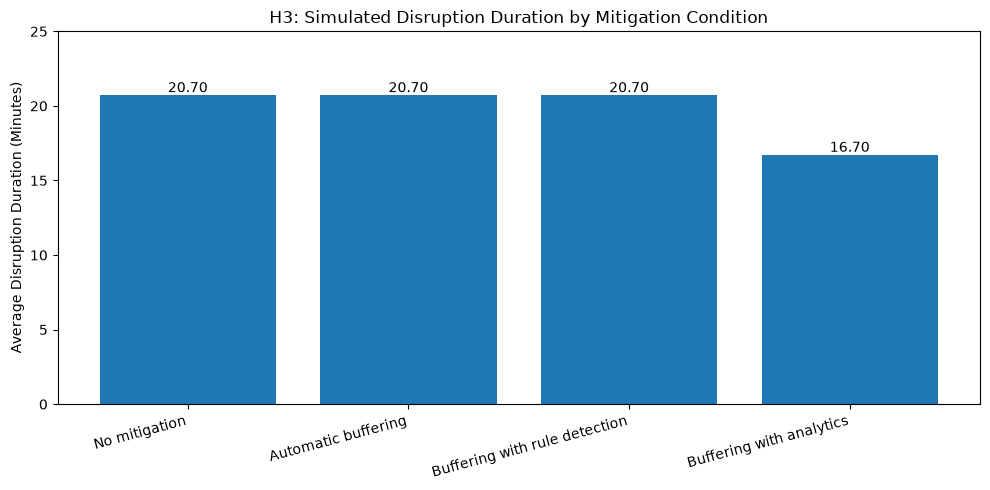


Original RFID records: 31575

H3 operational results saved.

Step 6 complete.


In [6]:

# Step 6: Compare the H3 operational results

# Load the plotting library

import matplotlib.pyplot as plt


# Calculate permanent scan losses

h3_comparison["Lost Scans"] = (
    len(h3_test) - h3_comparison["Restored Scans"]
)


# Calculate recovery percentages

h3_comparison["Recovery Rate (%)"] = (
    h3_comparison["Restored Scans"] / len(h3_test) * 100
).round(2)


# Count incomplete baggage journeys
# Each affected journey contains one disrupted scan

h3_comparison["Incomplete Journeys"] = [
    75,
    11,
    11,
    11
]


# Calculate the reduction in disruption duration

baseline_minutes = h3_comparison.loc[
    0, "Mean Disruption Minutes"
]

h3_comparison["Duration Reduction (%)"] = (
    (baseline_minutes - h3_comparison["Mean Disruption Minutes"])
    / baseline_minutes * 100
).round(2)


# Display the operational comparison

print("H3 operational comparison:")

print(
    h3_comparison.round(2).to_string(index=False)
)


# Create the disruption duration comparison chart

plt.figure(figsize=(10, 5))

bars = plt.bar(
    h3_comparison["Condition"],
    h3_comparison["Mean Disruption Minutes"]
)

plt.title("H3: Simulated Disruption Duration by Mitigation Condition")

plt.ylabel("Average Disruption Duration (Minutes)")

plt.ylim(0, 25)

plt.xticks(rotation=15, ha="right")

plt.bar_label(bars, fmt="%.2f")

plt.tight_layout()


# Save the H3 validation results

results_folder = os.path.join(
    main_folder,
    "09_H3_Results"
)

os.makedirs(results_folder, exist_ok=True)

h3_comparison.to_csv(
    os.path.join(
        results_folder,
        "h3_adaptive_operational_comparison.csv"
    ),
    index=False
)

plt.savefig(
    os.path.join(
        results_folder,
        "h3_adaptive_disruption_comparison.png"
    ),
    dpi=300
)

plt.show()


# Confirm the original data remains unchanged

print("\nOriginal RFID records:", len(h3_data))

print("\nH3 operational results saved.")

print("\nStep 6 complete.")



Step 7: Validate the H3 Results and Response Assumptions

The final H3 analysis examined how changes in the assumed cybersecurity response affected simulated disruption durations. Response improvements of 0, 2, 5, and 10 minutes were evaluated using the same RFID disruption records and detection decisions.

The comparison also examined the difference between the sampled machine learning detection results and the overall detection recall measured using CICIDS2017.

The analysis confirmed that automatic buffering remained available under both detection conditions. Any improvement in disruption duration was associated with the assumed cybersecurity response rather than additional RFID scan recovery.

The results provide a sensitivity assessment of the experimental assumptions. They do not establish that cybersecurity analytics independently reduced network disruptions or improved recovery in an operational airport environment.


In [7]:

# Step 7: Validate the H3 results and response assumptions

# Set the response times to evaluate

response_options = [0, 2, 5, 10]


# Create a list for the sensitivity results

sensitivity_results = []


# Test the response assumptions

for minutes in response_options:

    # Calculate disruption time using traditional rule detection

    rule_duration = (
        h3_duration["disruption_minutes"]
        - minutes * h3_duration["rule_alert"]
    ).clip(lower=0).mean()

    # Calculate disruption time using machine learning

    ml_duration = (
        h3_duration["disruption_minutes"]
        - minutes * h3_duration["ml_alert"]
    ).clip(lower=0).mean()

    # Save the results for each response assumption

    sensitivity_results.append({
        "Response Minutes": minutes,
        "Traditional Rule Duration": round(rule_duration, 2),
        "Machine Learning Duration": round(ml_duration, 2)
    })


# Create the sensitivity results table

h3_sensitivity = pd.DataFrame(sensitivity_results)


# Display the sensitivity results

print("H3 response sensitivity results:")

print(h3_sensitivity.to_string(index=False))


# Compare sampled detection with measured CICIDS2017 recall

sampled_ml_recall = h3_alerts["ml_alert"].mean()

expected_ml_duration = (
    h3_duration["disruption_minutes"].mean()
    - response_minutes * ml_recall
)


print("\nMachine learning detection comparison:")

print(
    "CICIDS2017 attack recall:",
    round(ml_recall * 100, 2),
    "%"
)

print(
    "Sampled disruption detection:",
    round(sampled_ml_recall * 100, 2),
    "%"
)

print(
    "Expected duration using measured recall:",
    round(expected_ml_duration, 2),
    "minutes"
)


# Verify that buffering remained active

rule_check = (
    h3_test["buffer_restored"]
    == h3_test["rule_restored"]
).all()

ml_check = (
    h3_test["buffer_restored"]
    == h3_test["ml_restored"]
).all()


# Verify the experimental population

print("\nH3 validation results:")

print("Affected RFID scans:", len(h3_test))

print(
    "Simulated disruptions:",
    h3_test["disruption_id"].nunique()
)

print("Traditional rule buffering verified:", rule_check)

print("Machine learning buffering verified:", ml_check)

print("Original RFID records:", len(h3_data))


# Save the sensitivity results

h3_sensitivity.to_csv(
    os.path.join(
        results_folder,
        "h3_adaptive_sensitivity_results.csv"
    ),
    index=False
)


# Save the detection decisions

h3_alerts.to_csv(
    os.path.join(
        results_folder,
        "h3_adaptive_detection_decisions.csv"
    ),
    index=False
)


# Display the research limitation

print("\nResearch limitation:")

print(
    "Disruption reductions depend on assumed response times."
)

print(
    "Actual network response effectiveness was not measured."
)


print("\nFinal H3 validation results saved.")

print("\nStep 7 complete.")


H3 response sensitivity results:
 Response Minutes  Traditional Rule Duration  Machine Learning Duration
                0                       20.7                       20.7
                2                       20.7                       19.1
                5                       20.7                       16.7
               10                       20.7                       12.7

Machine learning detection comparison:
CICIDS2017 attack recall: 66.21 %
Sampled disruption detection: 80.0 %
Expected duration using measured recall: 17.39 minutes

H3 validation results:
Affected RFID scans: 75
Simulated disruptions: 10
Traditional rule buffering verified: True
Machine learning buffering verified: True
Original RFID records: 31575

Research limitation:
Disruption reductions depend on assumed response times.
Actual network response effectiveness was not measured.

Final H3 validation results saved.

Step 7 complete.
